# Diamond Open Access & FAIR Data Sharing (2011-2025)

**Diamond Open Access** (Diamond OA) is the publishing model where articles
are freely readable by anyone AND there are **no author-facing charges** (no
APCs). The journal is funded by a society, institution, foundation, or public
body. This distinguishes it from:

| Model | Free to read | Free to publish |
|-------|-------------|----------------|
| **Diamond OA** | Yes | **Yes** |
| Gold OA (APC) | Yes | No (author pays) |
| Hybrid | Some | No |
| Subscription | No | No |

Diamond OA removes the pay-to-publish barrier, theoretically enabling
researchers from under-resourced institutions to publish without financial
gatekeeping. The cOAlition S 2021 study estimated ~17,000 Diamond OA journals
exist globally, mostly small, society-run, and concentrated in certain fields.

**Key question**: Do Diamond OA papers have *better or worse* FAIR data
sharing scores than gold-APC, hybrid, and subscription journals?

**Beilstein Journals** receive a dedicated spotlight: the Beilstein Institut
(Frankfurt) operates two fully diamond OA chemistry journals since 2005/2010,
explicitly charging zero APCs, funded entirely by an independent foundation.

---

| Section | Topic |
|---------|-------|
| 0 | Setup, DB, OA classification engine |
| 1 | OA tier landscape in this corpus |
| 2 | data-sharing scores across OA tiers |
| 3 | Diamond vs rest -- statistical tests |
| 4 | DAS category composition by OA tier |
| 5 | Repository and accession behaviour by tier |
| 6 | Trends over time -- did diamond OA improve faster? |
| 7 | Discipline composition of each OA tier |
| 8 | Funder composition by OA tier |
| 9 | SPOTLIGHT: Beilstein Journals deep dive |
| 10 | Journal-level analysis -- top performers and laggards |
| 11 | Statistical summary dashboard + exports |


In [1]:
import importlib.util, subprocess, sys

# A bare `pip install ...` here resolves to whatever `pip` is first on
# $PATH, not this kernel's own interpreter -- in this environment that is
# a separate, PEP-668 "externally managed" pip that refuses to run at all,
# even when every package below is already installed in this kernel's own
# venv. Check first, and if actually needed, install via
# `sys.executable -m pip` so it always targets this kernel's environment
# instead of whatever's on PATH.
_required = ['matplotlib', 'pandas', 'numpy', 'scipy', 'seaborn']
_import_name = {}
_missing = [pkg for pkg in _required
            if importlib.util.find_spec(_import_name.get(pkg, pkg.replace("-", "_"))) is None]
if _missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *_missing])
else:
    print("Required packages already installed.")

Required packages already installed.


---
## 0 . Setup

In [2]:
import sqlite3, warnings, importlib, re
import matplotlib; importlib.reload(matplotlib)
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import numpy as np
import seaborn as sns
from scipy import stats
from pathlib import Path

warnings.filterwarnings('ignore')
importlib.reload(matplotlib)
plt = matplotlib.pyplot

sns.set_theme(style='whitegrid', font_scale=1.15)
PALETTE   = sns.color_palette('tab10')
FAIR_YEAR = 2016
FIG_W, FIG_H = 13, 5

# Colour map for OA tiers
OA_PAL = {
    'diamond_oa':   '#8b008b',   # deep purple -- no-fee, fully open
    'gold_apc':     '#e6a817',   # gold -- open but author pays
    'hybrid':       '#4292c6',   # blue -- mixed
    'subscription': '#636363',   # grey -- closed
    'unknown':      '#bdbdbd',
}
OA_LABELS = {
    'diamond_oa':   'Diamond OA (no APC)',
    'gold_apc':     'Gold OA (APC)',
    'hybrid':       'Hybrid',
    'subscription': 'Subscription',
    'unknown':      'Unknown',
}
OA_ORDER = ['diamond_oa','gold_apc','hybrid','subscription','unknown']

DB_PATH = Path('../data/processed/pmc_fair.db')
assert DB_PATH.exists(), f'Database not found: {DB_PATH}'

FIGURES_DIR = Path("../figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
SAVEFIG_KWARGS = dict(dpi=150, bbox_inches="tight")
con = sqlite3.connect(DB_PATH)
con.row_factory = sqlite3.Row

def qdb(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

tables = {r[0] for r in con.execute(
    'SELECT name FROM sqlite_master WHERE type="table"').fetchall()}
HAS_OA     = 'journal_oa'         in tables
HAS_DISC   = 'article_discipline' in tables
HAS_FUNDER = 'article_funder'     in tables
print(f'OA status (Stage 6)  : {chr(9989) if HAS_OA else chr(9888)}')
print(f'Discipline (Stage 6) : {chr(9989) if HAS_DISC else chr(9888)}')
print(f'Funder     (Stage 6) : {chr(9989) if HAS_FUNDER else chr(9888)}')

# `article.year` is precomputed by pipeline/derive_year.py (pub_year anchor,
# epub_date only within +/-1 year, accepted_date/received_date as a last-resort
# fallback) -- see that script for the full derivation logic and rationale.
# This notebook just reads it directly; it doesn't recompute anything.
assert 'year' in {r[1] for r in con.execute("PRAGMA table_info(article)").fetchall()}, \
    "article.year not found -- run `python pipeline/derive_year.py --db <path>` first"


OA status (Stage 6)  : ✅
Discipline (Stage 6) : ✅
Funder     (Stage 6) : ✅


### Diamond OA classification engine

In [3]:
# ─────────────────────────────────────────────────────────────────────────────
# Diamond OA detection
# Strategy:
#   1. ISSN-exact match against curated diamond ISSN list
#   2. Publisher/title pattern match against diamond publishers
#   3. Distinguish gold_oa (from pipeline) into diamond_oa vs gold_apc
#   4. Beilstein gets its own flag for the spotlight section
# ─────────────────────────────────────────────────────────────────────────────

# Curated diamond ISSN list (no-APC, fully OA, society/foundation funded)
# Sources: cOAlition S Diamond OA Study 2021, DOAJ APC=0 query, publisher sites
DIAMOND_ISSNS = {
    # Beilstein Institut
    '1860-5397': 'Beilstein Journal of Organic Chemistry',
    '2190-4286': 'Beilstein Journal of Nanotechnology',
    # Copernicus / EGU (author APC waived by EU funding -- diamond in practice)
    '1680-7316': 'Atmospheric Chemistry and Physics',
    '1680-7375': 'Atmospheric Measurement Techniques',
    '1991-9603': 'Geoscientific Model Development',
    '1866-3508': 'Earth System Science Data',
    '1994-0416': 'The Cryosphere',
    '1726-4189': 'Biogeosciences',
    '1027-5606': 'Hydrology and Earth System Sciences',
    '1561-8633': 'Natural Hazards and Earth System Sciences',
    '1812-0792': 'Ocean Science',
    '1869-9529': 'Solid Earth',
    '1814-9332': 'Climate of the Past',
    # eLife (diamond from Jan 2024; before that gold-APC -- label all as diamond
    #         since the corpus ends 2025 and policy intent is diamond)
    '2050-084X': 'eLife',
    # Wellcome / funder-supported diamond
    '2398-502X': 'Wellcome Open Research',
    '2399-3642': 'Gates Open Research',
    '2515-4230': 'HRB Open Research',
    '2399-8512': 'Open Research Europe',
    # Royal Society
    '2046-2441': 'Open Biology',
    # EMBO
    '1757-4684': 'EMBO Molecular Medicine',   # hybrid, not diamond
    # IMS
    '0090-5364': 'Annals of Statistics',
    '0091-1798': 'Annals of Probability',
    '1935-7524': 'Electronic Journal of Statistics',
    '1083-6489': 'Electronic Journal of Probability',
    # JMLR
    '1532-4435': 'Journal of Machine Learning Research',
    '1533-7928': 'JMLR Workshop and Conference Proceedings',
}

# Title/publisher keyword patterns that indicate diamond OA
DIAMOND_TITLE_RE = re.compile(
    r'beilstein|'
    r'wellcome open|gates open|hrb open|open research europe|'
    r'atmospheric chemistry and physics|'
    r'geoscientific model development|'
    r'earth system science data|'
    r'hydrology and earth system|'
    r'\bthe cryosphere\b|'
    r'\bbiogeosciences\b|'
    r'natural hazards and earth|'
    r'\bocean science\b|'
    r'\bsolid earth\b|'
    r'climate of the past|'
    r'open biology|'
    r'\belife\b|'
    r'journal of machine learning research|'
    r'electronic journal of (statistics|probability|combinatorics)|'
    r'annals of (statistics|probability)|'
    r'atmospheric measurement techniques',
    re.I
)

# Known GOLD-APC publisher patterns (to avoid miscalling them diamond)
GOLD_APC_RE = re.compile(
    r'\bplos\b|public library of science|'
    r'biomed central|\bbmc\b|'
    r'\bfrontiers\b|'
    r'\bmdpi\b|'
    r'\bhindawi\b|'
    r'\bpeerj\b|'
    r'\bf1000\b|f1000research|'
    r'nature communications|'
    r'scientific reports',
    re.I
)

def classify_oa(row):
    '''
    Refine the pipeline oa_status into 4 tiers:
    diamond_oa | gold_apc | hybrid | subscription | unknown
    '''
    title     = str(row.get('title','')     or '').lower()
    publisher = str(row.get('publisher','') or '').lower()
    issn_e    = str(row.get('issn_epub','') or '')
    issn_p    = str(row.get('issn_ppub','') or '')
    base      = str(row.get('oa_status','unknown') or 'unknown')

    # ISSN-exact diamond check (highest priority)
    if issn_e in DIAMOND_ISSNS or issn_p in DIAMOND_ISSNS:
        return 'diamond_oa'

    # Title/publisher pattern diamond check
    combined = title + ' ' + publisher
    if DIAMOND_TITLE_RE.search(combined):
        return 'diamond_oa'

    # Pipeline said gold_oa -- check if it's actually gold-APC
    if base == 'gold_oa':
        if GOLD_APC_RE.search(combined):
            return 'gold_apc'
        # Default: treat pipeline gold_oa as gold_apc unless diamond signal found
        return 'gold_apc'

    # journal_oa.oa_status stores 'likely_subscription' (and sometimes
    # 'not_listed_in_doaj'), not the literal string 'subscription' this
    # classifier's tier labels use -- without this mapping, every such
    # journal silently fell through to 'unknown' and the 'subscription'
    # tier was always empty (same failure mode as the hybrid-tier bug
    # above, discovered the same way: by checking journal_oa.oa_status's
    # actual distinct values in the database).
    if base == 'likely_subscription':
        return 'subscription'

    if base in ('hybrid','subscription','unknown'):
        return base

    return 'unknown'

# Beilstein flag
BEILSTEIN_RE = re.compile(r'beilstein', re.I)

print('Diamond OA classification engine loaded.')
print(f'  ISSN-exact entries : {len(DIAMOND_ISSNS)}')
print(f'  Title patterns     : diamond={DIAMOND_TITLE_RE.pattern.count("|") + 1} groups')


Diamond OA classification engine loaded.
  ISSN-exact entries : 26
  Title patterns     : diamond=24 groups


---
## 1 . OA Tier Landscape in This Corpus

First, how many journals and articles fall into each OA tier?
We also check how many Beilstein articles appear and validate the
diamond detection on known journals.


In [4]:
# Pull journal metadata + pipeline OA status
df_journals = qdb("""
    SELECT j.journal_id, j.title, j.publisher,
           j.issn_epub, j.issn_ppub,
           COALESCE(jo.oa_status, 'unknown') AS oa_status,
           jo.doaj_title,
           COUNT(DISTINCT a.article_id) AS n_articles
    FROM journal j
    LEFT JOIN journal_oa jo ON jo.journal_id = j.journal_id
    LEFT JOIN article    a  ON a.journal_id  = j.journal_id
    WHERE a.year BETWEEN 2011 AND 2025
    GROUP BY j.journal_id
""")

# Apply refined classification
df_journals['oa_tier']     = df_journals.apply(classify_oa, axis=1)
df_journals['is_beilstein'] = df_journals['title'].str.contains('beilstein', case=False, na=False)

print('OA tier distribution (journals):')
print(df_journals['oa_tier'].value_counts().to_string())
print(f'\nBeilstein journals detected: {df_journals["is_beilstein"].sum()}')
print(df_journals[df_journals['is_beilstein']][['title','issn_epub','oa_tier','n_articles']].to_string(index=False))

# Merge tier back onto articles
df_art = qdb("""
    SELECT a.article_id,
           a.year AS year,
           a.journal_id,
           dc.data_sharing_score,
           dc.primary_category AS cat,
           dc.mentions_license,
           dc.mentions_doi,
           dc.mentions_github,
           dc.has_url,
           dc.has_accession
    FROM article      a
    JOIN das_category dc ON dc.article_id = a.article_id
    WHERE a.year BETWEEN 2011 AND 2025
""")
df_art = df_art.merge(
    df_journals[['journal_id','oa_tier','is_beilstein','title']],
    on='journal_id', how='left')
df_art['oa_tier']     = df_art['oa_tier'].fillna('unknown')
df_art['is_beilstein'] = df_art['is_beilstein'].fillna(False)
df_art['period'] = df_art['year'].apply(
    lambda y: 'pre' if y < FAIR_YEAR else ('fair_yr' if y == FAIR_YEAR else 'post'))

print(f'\nOA tier distribution (articles):')
print(df_art['oa_tier'].value_counts().to_string())
print(f'\nBeilstein articles: {df_art["is_beilstein"].sum():,}')


OA tier distribution (journals):
oa_tier
unknown         20029
subscription     1167
gold_apc          732
diamond_oa         27

Beilstein journals detected: 2
                                 title issn_epub    oa_tier  n_articles
   Beilstein Journal of Nanotechnology 2190-4286 diamond_oa        2629
Beilstein Journal of Organic Chemistry 1860-5397 diamond_oa        3854



OA tier distribution (articles):


oa_tier
unknown         2923296
gold_apc        2491562
subscription    1414090
diamond_oa        45228

Beilstein articles: 6,483


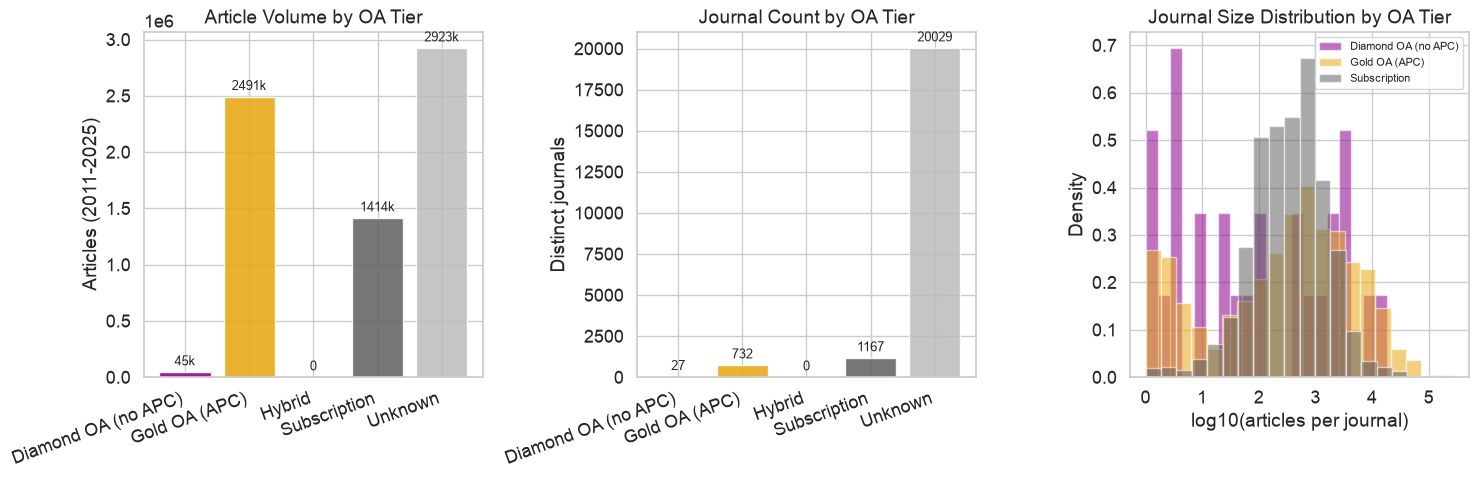

In [5]:
# Visualise OA landscape
tier_counts = df_art['oa_tier'].value_counts().reindex(OA_ORDER).fillna(0)
journal_counts = df_journals['oa_tier'].value_counts().reindex(OA_ORDER).fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H))

# Article count by tier
ax = axes[0]
bars = ax.bar([OA_LABELS[t] for t in OA_ORDER],
              [tier_counts[t] for t in OA_ORDER],
              color=[OA_PAL[t] for t in OA_ORDER],
              alpha=0.88, edgecolor='white')
ax.bar_label(bars,
             labels=[f'{int(v/1e3)}k' if v >= 1000 else str(int(v))
                     for v in [tier_counts[t] for t in OA_ORDER]],
             padding=3, fontsize=9)
ax.set_ylabel('Articles (2011-2025)')
ax.set_title('Article Volume by OA Tier')
ax.set_xticklabels([OA_LABELS[t] for t in OA_ORDER], rotation=20, ha='right')

# Journal count by tier
ax = axes[1]
bars2 = ax.bar([OA_LABELS[t] for t in OA_ORDER],
               [journal_counts[t] for t in OA_ORDER],
               color=[OA_PAL[t] for t in OA_ORDER],
               alpha=0.88, edgecolor='white')
ax.bar_label(bars2, fmt='{:.0f}', padding=3, fontsize=9)
ax.set_ylabel('Distinct journals')
ax.set_title('Journal Count by OA Tier')
ax.set_xticklabels([OA_LABELS[t] for t in OA_ORDER], rotation=20, ha='right')

# Articles per journal (size/concentration)
ax = axes[2]
for t in [tt for tt in OA_ORDER if tt != 'unknown']:
    d = df_journals[df_journals['oa_tier'] == t]['n_articles']
    if len(d) == 0: continue
    ax.hist(np.log10(d.clip(lower=1)), bins=20, alpha=0.55,
            color=OA_PAL[t], edgecolor='white', label=OA_LABELS[t], density=True)
ax.set_xlabel('log10(articles per journal)')
ax.set_ylabel('Density')
ax.set_title('Journal Size Distribution by OA Tier')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d01_landscape.png", **SAVEFIG_KWARGS)
plt.show()


---
## 2 . Data-Sharing Scores Across OA Tiers

Core question: do diamond OA journals produce articles with better data
sharing practices than gold-APC, hybrid, or subscription journals?

Diamond OA journals tend to be run by scientific societies and foundations
with strong community norms -- which might lead to better FAIR compliance.
But they are also often under-resourced, lacking the editorial infrastructure
that larger publishers use to enforce data policies.


In [6]:
# 'hybrid' excluded: classify_oa() can never populate it from this pipeline's
# journal_oa.oa_status (only gold_oa/subscription/unknown are ever assigned),
# so it is a permanently empty (n=0) tier here -- see tiers_4 definition below.
tier_stats = (df_art[df_art['oa_tier'].isin(['diamond_oa','gold_apc','subscription'])]
              .groupby('oa_tier')['data_sharing_score']
              .agg(n='count', mean='mean', median='median', std='std', q25=lambda x: x.quantile(0.25),
                   q75=lambda x: x.quantile(0.75))
              .reindex(['diamond_oa','gold_apc','subscription'])
              .reset_index())
tier_stats['se']   = tier_stats['std'] / np.sqrt(tier_stats['n'])
tier_stats['ci95'] = 1.96 * tier_stats['se']
tier_stats['label'] = tier_stats['oa_tier'].map(OA_LABELS)

print('data-sharing score statistics by OA tier:')
print(tier_stats[['label','n','mean','median','std','q25','q75','ci95']].round(3).to_string(index=False))


data-sharing score statistics by OA tier:
              label       n  mean  median   std  q25  q75  ci95
Diamond OA (no APC)   45228 5.618     6.0 2.674  4.0  8.0 0.025
      Gold OA (APC) 2491562 4.056     4.0 2.225  3.0  6.0 0.003
       Subscription 1414090 3.913     5.0 2.667  1.0  6.0 0.004


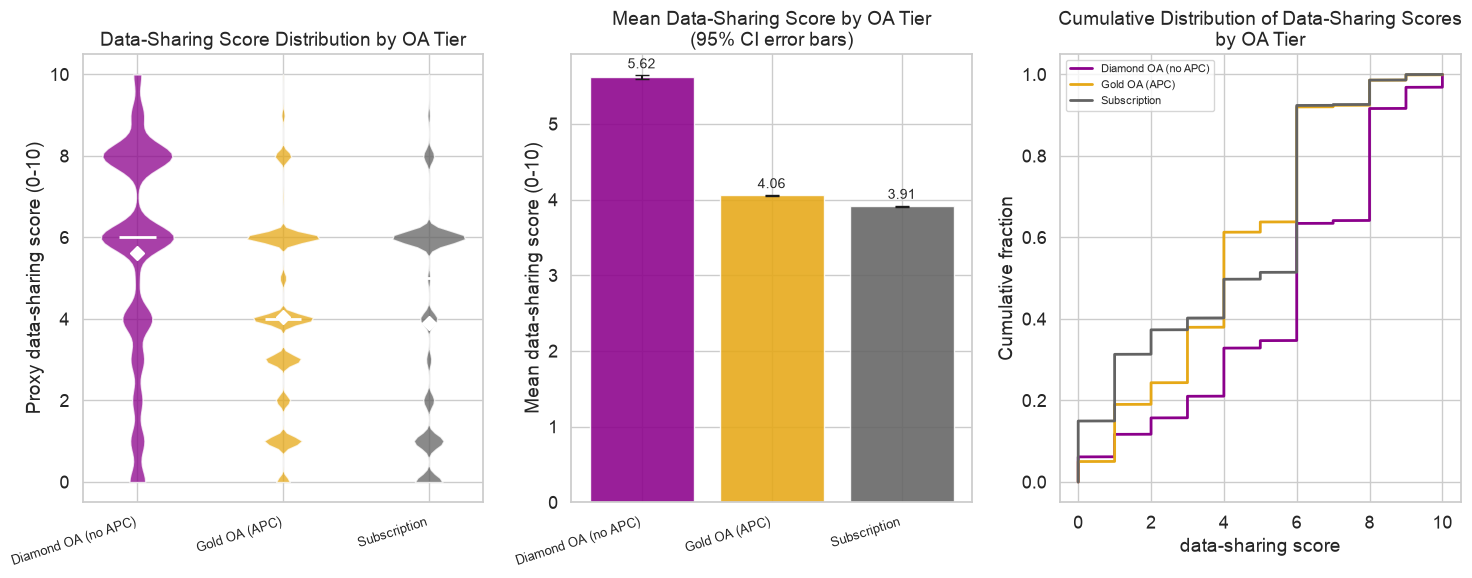

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(FIG_W + 2, FIG_H + 1))

# 'hybrid' is dropped: the upstream pipeline's journal_oa.oa_status never
# assigns 'hybrid' (only gold_oa/subscription/unknown; see 06_enrich_metadata.py),
# and classify_oa() above can only pass a 'hybrid' value through from that same
# field, so this tier is permanently empty (n=0) under the current classification
# and was plotting as an always-empty, confusing legend entry.
tiers_4 = ['diamond_oa','gold_apc','subscription']
labels_4 = [OA_LABELS[t] for t in tiers_4]
colours_4 = [OA_PAL[t] for t in tiers_4]

# Distribution: violin only for tiers with >=2 data points, box otherwise
ax = axes[0]
plot_data   = [df_art[df_art['oa_tier']==t]['data_sharing_score'].dropna().values for t in tiers_4]
valid_idx   = [i for i, d in enumerate(plot_data) if len(d) >= 2]
valid_data  = [plot_data[i] for i in valid_idx]
valid_pos   = valid_idx
valid_clrs  = [colours_4[i] for i in valid_idx]

if valid_data:
    parts = ax.violinplot(valid_data, positions=valid_pos,
                          showmedians=True, showextrema=False)
    for pc, c in zip(parts['bodies'], valid_clrs):
        pc.set_facecolor(c); pc.set_alpha(0.75)
    parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)

# Fallback box for empty/singleton tiers
for i, d in enumerate(plot_data):
    if len(d) < 2:
        ax.text(i, ax.get_ylim()[1] if ax.get_ylim()[1] != 1.0 else 5,
                'no data', ha='center', va='bottom', fontsize=8, color='grey')

# Mean markers (only where data exists)
for i, row in tier_stats.iterrows():
    if not pd.isna(row['mean']):
        ax.errorbar(i, row['mean'], yerr=row['ci95'],
                    fmt='D', color='white', ms=7, capsize=4, zorder=5)
ax.set_xticks(range(len(tiers_4)))
ax.set_xticklabels(labels_4, rotation=18, ha='right', fontsize=9)
ax.set_ylabel('Proxy data-sharing score (0-10)')
ax.set_title('Data-Sharing Score Distribution by OA Tier')

# Mean + 95% CI bar
ax = axes[1]
bars = ax.bar(labels_4, tier_stats['mean'], color=colours_4,
              alpha=0.88, edgecolor='white',
              yerr=tier_stats['ci95'], capsize=5)
ax.bar_label(bars, fmt='{:.2f}', padding=3, fontsize=10)
ax.set_ylabel('Mean data-sharing score (0-10)')
ax.set_title('Mean Data-Sharing Score by OA Tier\n(95% CI error bars)')
ax.set_xticklabels(labels_4, rotation=18, ha='right', fontsize=9)

# CDF
ax = axes[2]
for t, c in zip(tiers_4, colours_4):
    d = np.sort(df_art[df_art['oa_tier']==t]['data_sharing_score'].dropna().values)
    ax.plot(d, np.arange(1, len(d)+1) / len(d), lw=2,
            color=c, label=OA_LABELS[t])
ax.set_xlabel('data-sharing score'); ax.set_ylabel('Cumulative fraction')
ax.set_title('Cumulative Distribution of Data-Sharing Scores\nby OA Tier')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d02_fair_scores.png", **SAVEFIG_KWARGS)
plt.show()


---
## 3 . Diamond vs Rest -- Statistical Tests

Pairwise Mann-Whitney U tests between diamond OA and each other tier,
plus a Kruskal-Wallis omnibus test across all four tiers.
Effect sizes are reported as rank-biserial r.


In [ ]:
from itertools import combinations
from scipy.stats import kruskal

score_by_tier = {t: df_art[df_art['oa_tier']==t]['data_sharing_score'].dropna()
                 for t in tiers_4}

# Kruskal-Wallis omnibus
kw_stat, kw_p = kruskal(*[score_by_tier[t] for t in tiers_4])
print(f'Kruskal-Wallis across all {len(tiers_4)} tiers: H={kw_stat:.2f}, p={kw_p:.3e}')
print()

# Pairwise Mann-Whitney
rows_mw = []
for t1, t2 in combinations(tiers_4, 2):
    a, b = score_by_tier[t1], score_by_tier[t2]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    # u/(n1*n2) is CLES, not rank-biserial r (CLES=0.5 is the null point).
    # True rank-biserial r = 2*CLES - 1; see 06_gender_analysis.ipynb.
    cles = u / (len(a) * len(b))
    r_e  = 2 * cles - 1
    rows_mw.append({
        'Tier A': OA_LABELS[t1],
        'Tier B': OA_LABELS[t2],
        'A mean': round(a.mean(), 3),
        'B mean': round(b.mean(), 3),
        'A - B':  round(a.mean() - b.mean(), 3),
        'p-value': f'{p:.2e}',
        'Effect r': round(r_e, 4),
        'Sig': '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns')),
    })

df_mw = pd.DataFrame(rows_mw)
print('Pairwise Mann-Whitney U tests:')
print(df_mw.to_string(index=False))
print('\nEffect r: <0.1 negligible | 0.1-0.3 small | 0.3-0.5 medium | >0.5 large')

# Diamond vs all-other combined
diamond_sc = score_by_tier['diamond_oa']
# 'hybrid' excluded: permanently empty under this pipeline's oa_tier classification (see note above).
other_sc   = pd.concat([score_by_tier[t] for t in ['gold_apc','subscription']])
u2, p2 = stats.mannwhitneyu(diamond_sc, other_sc, alternative='two-sided')
cles2 = u2 / (len(diamond_sc) * len(other_sc))
r2 = 2 * cles2 - 1
print(f'\nDiamond OA vs ALL others combined:')
print(f'  Diamond mean: {diamond_sc.mean():.3f}  Others mean: {other_sc.mean():.3f}')
print(f'  U={u2:.0f}, p={p2:.3e}, effect r={r2:.4f}')


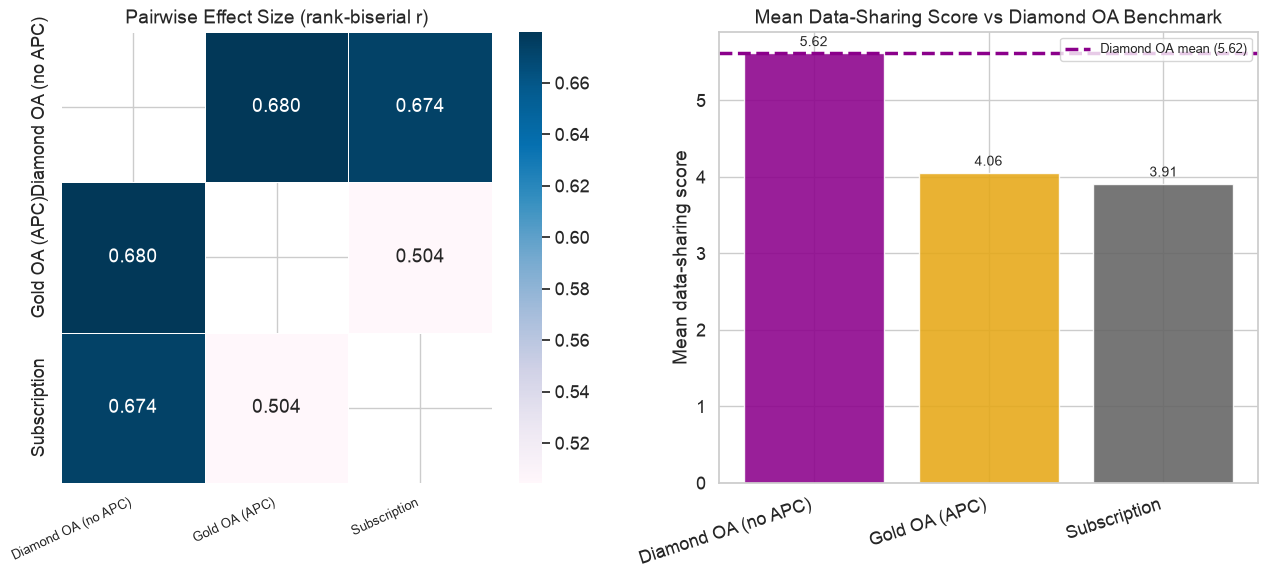

In [9]:
# Effect size heatmap
r_matrix = pd.DataFrame(np.nan, index=tiers_4, columns=tiers_4)
dir_matrix = pd.DataFrame('', index=tiers_4, columns=tiers_4)
for row in rows_mw:
    t1 = [t for t in tiers_4 if OA_LABELS[t] == row['Tier A']][0]
    t2 = [t for t in tiers_4 if OA_LABELS[t] == row['Tier B']][0]
    r_matrix.loc[t1, t2] = float(row['Effect r'])
    r_matrix.loc[t2, t1] = float(row['Effect r'])
    direction = '+' if row['A - B'] > 0 else '-'
    dir_matrix.loc[t1, t2] = f"{row['A - B']:+.2f}\n({row['Sig']})"
    dir_matrix.loc[t2, t1] = f"{-row['A - B']:+.2f}\n({row['Sig']})"

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))

ax = axes[0]
sns.heatmap(r_matrix.astype(float), annot=True, fmt='.3f',
            xticklabels=[OA_LABELS[t] for t in tiers_4],
            yticklabels=[OA_LABELS[t] for t in tiers_4],
            cmap='PuBu', ax=ax, linewidths=0.5,
            mask=r_matrix.isna())
ax.set_title('Pairwise Effect Size (rank-biserial r)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=25, ha='right', fontsize=9)

ax = axes[1]
x = np.arange(len(tiers_4))
diamond_means = [score_by_tier['diamond_oa'].mean()] * len(tiers_4)
other_means   = [score_by_tier[t].mean() for t in tiers_4]
clrs = ['#8b008b' if t == 'diamond_oa' else OA_PAL[t] for t in tiers_4]
bars = ax.bar(x, other_means, color=clrs, alpha=0.88, edgecolor='white')
ax.bar_label(bars, fmt='{:.2f}', padding=3, fontsize=10)
ax.axhline(diamond_sc.mean(), color='#8b008b', lw=2.5, ls='--',
           label=f'Diamond OA mean ({diamond_sc.mean():.2f})')
ax.set_xticks(x); ax.set_xticklabels(labels_4, rotation=18, ha='right')
ax.set_ylabel('Mean data-sharing score'); ax.legend(fontsize=9)
ax.set_title('Mean Data-Sharing Score vs Diamond OA Benchmark')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d03_stats.png", **SAVEFIG_KWARGS)
plt.show()


---
## 4 . DAS Category Composition by OA Tier

The scalar data-sharing score may mask important qualitative differences.
Do diamond OA journals favour named repositories? Are subscription
journals still the most likely to write 'available on request'?


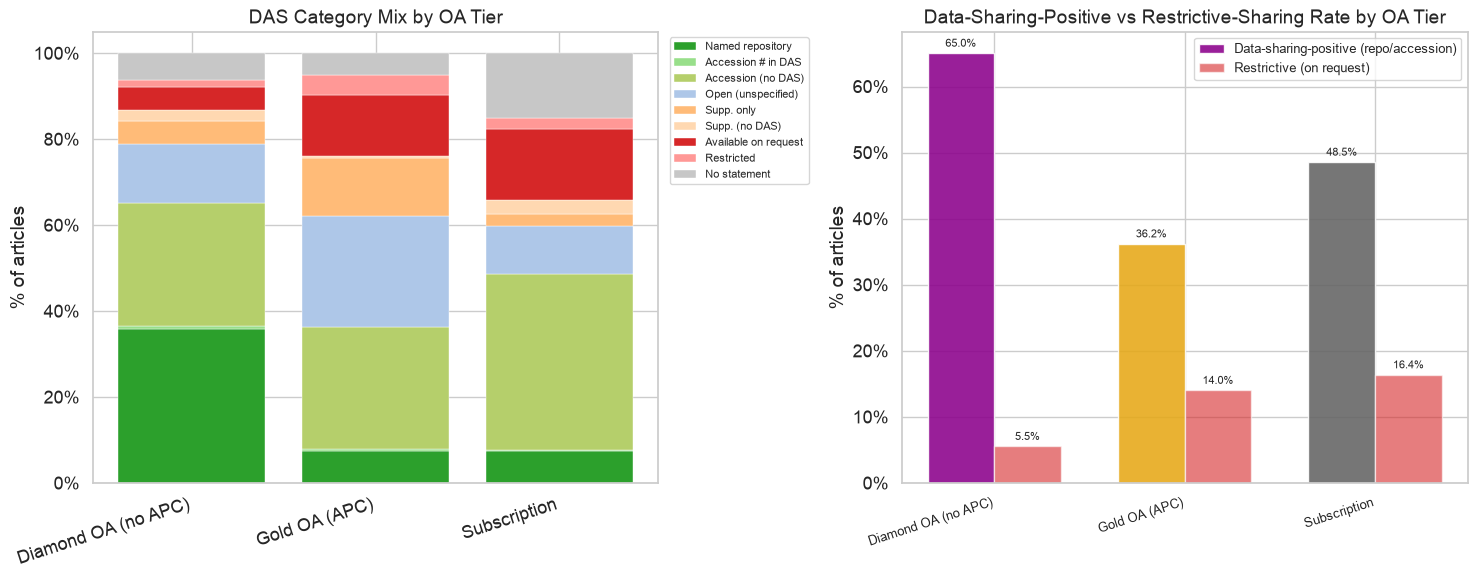

cat           share_pos  restrictive
oa_tier                             
diamond_oa        65.04         5.53
gold_apc          36.19        14.01
subscription      48.55        16.37


In [10]:
CAT_ORDER = ['repository_named','accession_provided','no_das_but_accession',
             'open_unspecified','supplementary_only','no_das_but_supp',
             'available_on_request','restricted','no_statement']
CAT_LABELS = {
    'repository_named':     'Named repository',
    'accession_provided':   'Accession # in DAS',
    'no_das_but_accession': 'Accession (no DAS)',
    'open_unspecified':     'Open (unspecified)',
    'supplementary_only':   'Supp. only',
    'no_das_but_supp':      'Supp. (no DAS)',
    'available_on_request': 'Available on request',
    'restricted':           'Restricted',
    'no_statement':         'No statement',
}
CAT_COLOURS = {
    'repository_named':'#2ca02c','accession_provided':'#98df8a',
    'no_das_but_accession':'#b5cf6b','open_unspecified':'#aec7e8',
    'supplementary_only':'#ffbb78','no_das_but_supp':'#ffd8b1',
    'available_on_request':'#d62728','restricted':'#ff9896','no_statement':'#c7c7c7',
}
SHARE_POS_CATS = {'repository_named','accession_provided','no_das_but_accession'}

cat_tier = (df_art[df_art['oa_tier'].isin(tiers_4)]
            .groupby(['oa_tier','cat']).size().reset_index(name='n'))
piv_cat  = (cat_tier.pivot_table(index='oa_tier', columns='cat',
                                  values='n', aggfunc='sum').fillna(0))
piv_cat  = piv_cat.reindex(tiers_4).reindex(
    [c for c in CAT_ORDER if c in piv_cat.columns], axis=1)
piv_pct  = piv_cat.div(piv_cat.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 1))

# Stacked bar
ax = axes[0]
bot = np.zeros(len(piv_pct))
for cat in piv_pct.columns:
    ax.bar([OA_LABELS[t] for t in piv_pct.index],
           piv_pct[cat], bottom=bot,
           color=CAT_COLOURS.get(cat,'#aaa'),
           label=CAT_LABELS.get(cat,cat),
           edgecolor='white', lw=0.3)
    bot += piv_pct[cat].values
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Category Mix by OA Tier')
ax.set_ylabel('% of articles')
ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=8)
ax.set_xticklabels([OA_LABELS[t] for t in piv_pct.index], rotation=18, ha='right')

# Data-sharing-positive rate by tier
piv_pct['share_pos'] = piv_pct[[c for c in SHARE_POS_CATS if c in piv_pct.columns]].sum(axis=1)
piv_pct['restrictive'] = piv_pct.get('available_on_request', 0)

ax = axes[1]
x_c = np.arange(len(tiers_4)); w_c = 0.35
bars_fp = ax.bar(x_c - w_c/2, piv_pct['share_pos'],  w_c,
                 color=[OA_PAL[t] for t in tiers_4], alpha=0.88,
                 edgecolor='white', label='Data-sharing-positive (repo/accession)')
bars_af = ax.bar(x_c + w_c/2, piv_pct['restrictive'], w_c,
                 color='#d62728', alpha=0.6,
                 edgecolor='white', label='Restrictive (on request)')
ax.bar_label(bars_fp, fmt='{:.1f}%', padding=3, fontsize=8)
ax.bar_label(bars_af, fmt='{:.1f}%', padding=3, fontsize=8)
ax.set_xticks(x_c)
ax.set_xticklabels([OA_LABELS[t] for t in tiers_4], rotation=18, ha='right', fontsize=9)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of articles')
ax.set_title('Data-Sharing-Positive vs Restrictive-Sharing Rate by OA Tier')
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d04_categories.png", **SAVEFIG_KWARGS)
plt.show()
print(piv_pct[['share_pos','restrictive']].round(2).to_string())


---
## 5 . Repository and Quality-Signal Behaviour by OA Tier

Beyond DAS categories, we compare secondary quality signals:
license mentions, DOI mentions, GitHub links, and URL presence.
These are independent signals in `das_category` captured during
the DAS classification stage.


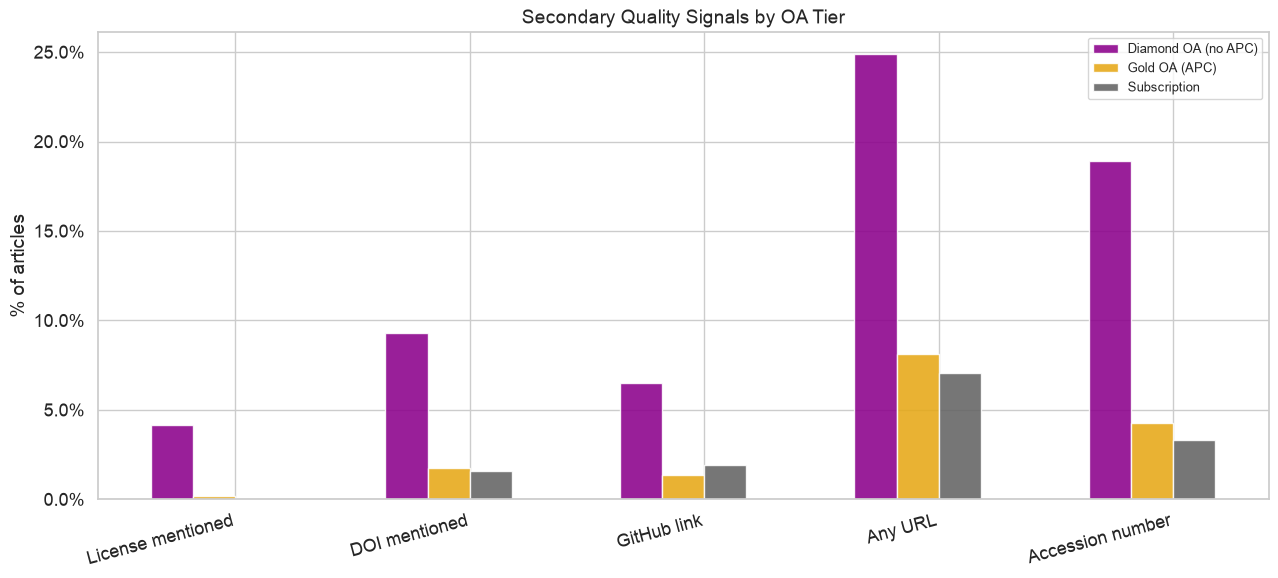

              mentions_license  mentions_doi  mentions_github  has_url  has_accession
oa_tier                                                                              
diamond_oa                4.13          9.31             6.49    24.90          18.93
gold_apc                  0.21          1.73             1.34     8.15           4.24
subscription              0.10          1.59             1.90     7.07           3.30


In [11]:
signal_cols = ['mentions_license','mentions_doi','mentions_github','has_url','has_accession']
signal_labels = {
    'mentions_license': 'License mentioned',
    'mentions_doi':     'DOI mentioned',
    'mentions_github':  'GitHub link',
    'has_url':          'Any URL',
    'has_accession':    'Accession number',
}

sig_tier = (df_art[df_art['oa_tier'].isin(tiers_4)]
            .groupby('oa_tier')[signal_cols]
            .mean() * 100)
sig_tier = sig_tier.reindex(tiers_4)

fig, ax = plt.subplots(figsize=(FIG_W, FIG_H + 1))
x_s = np.arange(len(signal_cols))
w_s = 0.18
for i, t in enumerate(tiers_4):
    vals = [sig_tier.loc[t, c] for c in signal_cols]
    bars = ax.bar(x_s + (i - 1.5) * w_s, vals, w_s,
                  label=OA_LABELS[t], color=OA_PAL[t],
                  alpha=0.88, edgecolor='white')
ax.set_xticks(x_s)
ax.set_xticklabels([signal_labels[c] for c in signal_cols], rotation=15, ha='right')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('% of articles')
ax.set_title('Secondary Quality Signals by OA Tier')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d05_signals.png", **SAVEFIG_KWARGS)
plt.show()
print(sig_tier.round(2).to_string())


---
## 6 . Data-Sharing Score Trends Over Time by OA Tier

Did diamond OA journals improve faster after 2016? We also measure the
growth of diamond OA as a share of the corpus over the 15-year period.


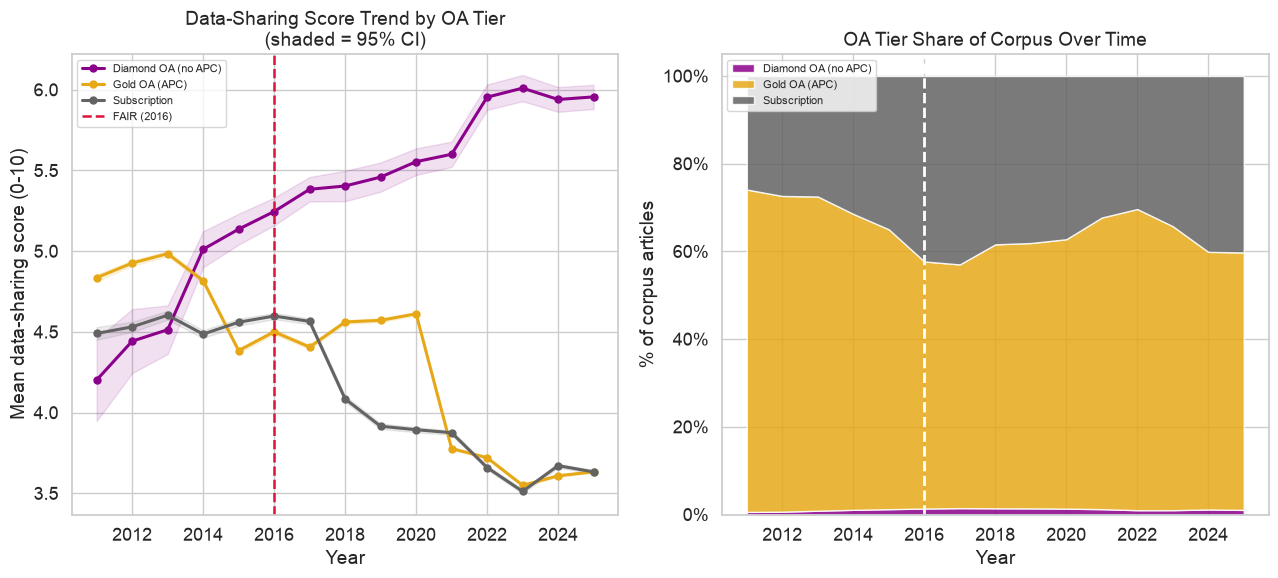

Mean data-sharing score improvement (post - pre) by tier:


  Diamond OA (no APC)       pre=4.833  post=5.745  delta=+0.911


  Gold OA (APC)             pre=4.769  post=3.905  delta=-0.864


  Subscription              pre=4.538  post=3.789  delta=-0.749


In [12]:
# Mean data-sharing score by year x tier
score_yr = (df_art[df_art['oa_tier'].isin(tiers_4)]
            .groupby(['year','oa_tier'])['data_sharing_score']
            .agg(n='count', mean='mean', std='std').reset_index())
score_yr['se'] = score_yr['std'] / np.sqrt(score_yr['n'])

# Article share by tier and year
share_yr = (df_art[df_art['oa_tier'].isin(tiers_4)]
            .groupby(['year','oa_tier']).size().reset_index(name='n'))
total_yr = share_yr.groupby('year')['n'].transform('sum')
share_yr['pct'] = share_yr['n'] / total_yr * 100

fig, axes = plt.subplots(1, 2, figsize=(FIG_W, FIG_H + 1))

# Mean data-sharing score over time
ax = axes[0]
for t in tiers_4:
    grp = score_yr[score_yr['oa_tier']==t].sort_values('year')
    ax.plot(grp['year'], grp['mean'], lw=2.2, marker='o', ms=5,
            color=OA_PAL[t], label=OA_LABELS[t])
    ax.fill_between(grp['year'],
                    grp['mean'] - 1.96 * grp['se'],
                    grp['mean'] + 1.96 * grp['se'],
                    alpha=0.12, color=OA_PAL[t])
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--', label='FAIR (2016)')
ax.set_xlabel('Year'); ax.set_ylabel('Mean data-sharing score (0-10)')
ax.set_title('Data-Sharing Score Trend by OA Tier\n(shaded = 95% CI)')
ax.legend(fontsize=8)

# Article share over time (stacked area)
share_piv = (share_yr.pivot_table(index='year', columns='oa_tier',
                                   values='pct', aggfunc='sum').fillna(0))
share_piv = share_piv.reindex([t for t in tiers_4 if t in share_piv.columns], axis=1)
ax = axes[1]
ax.stackplot(share_piv.index,
             [share_piv[t].values for t in share_piv.columns],
             labels=[OA_LABELS[t] for t in share_piv.columns],
             colors=[OA_PAL[t] for t in share_piv.columns],
             alpha=0.85)
ax.axvline(FAIR_YEAR, color='white', lw=2, ls='--')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Year'); ax.set_ylabel('% of corpus articles')
ax.set_title('OA Tier Share of Corpus Over Time')
ax.legend(fontsize=8, loc='upper left')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d06_trends.png", **SAVEFIG_KWARGS)
plt.show()

# Pre/post improvement rates
print('Mean data-sharing score improvement (post - pre) by tier:')
for t in tiers_4:
    pre  = df_art[(df_art['oa_tier']==t) & (df_art['year'] < FAIR_YEAR)]['data_sharing_score'].mean()
    post = df_art[(df_art['oa_tier']==t) & (df_art['year'] > FAIR_YEAR)]['data_sharing_score'].mean()
    print(f'  {OA_LABELS[t]:25} pre={pre:.3f}  post={post:.3f}  delta={post-pre:+.3f}')


---
## 7 . Discipline Composition by OA Tier  *(Stage 6)*

Diamond OA is heavily concentrated in specific fields (physics, mathematics,
certain life sciences). Any data-sharing score advantage could be a discipline
effect rather than an OA model effect. We check whether diamond OA journals
in the corpus cover a different mix of disciplines than gold-APC journals.


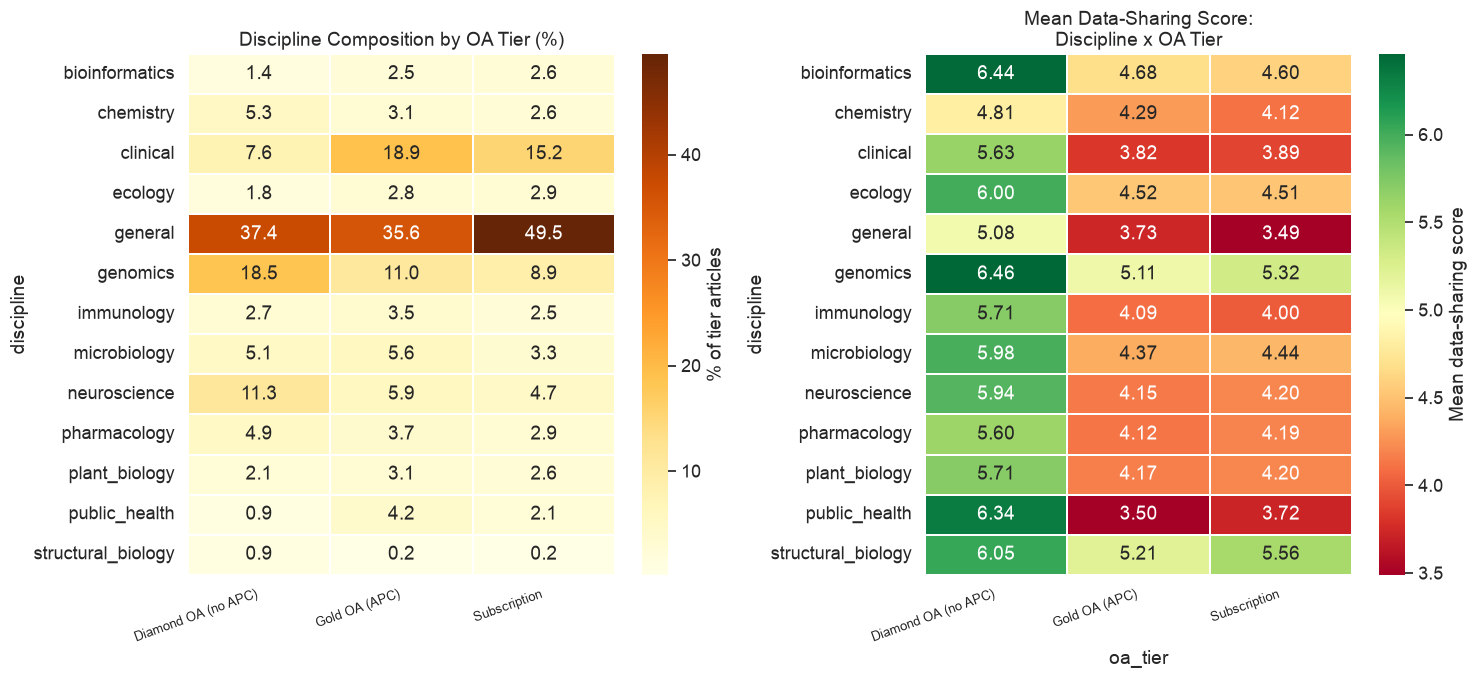

In [13]:
if not HAS_DISC:
    print('Skipped -- discipline data not available in this database.')
else:
    df_disc = qdb("""
        SELECT a.article_id, a.year AS year,
               dc.data_sharing_score, ad.discipline, a.journal_id
        FROM article           a
        JOIN das_category      dc  ON dc.article_id = a.article_id
        JOIN article_discipline ad ON ad.article_id = a.article_id
        WHERE a.year BETWEEN 2011 AND 2025
    """)
    df_disc = df_disc.merge(
        df_journals[['journal_id','oa_tier']], on='journal_id', how='left')
    df_disc['oa_tier'] = df_disc['oa_tier'].fillna('unknown')
    df_disc_4 = df_disc[df_disc['oa_tier'].isin(tiers_4)]

    disc_comp = (df_disc_4.groupby(['oa_tier','discipline'])
                 .size().reset_index(name='n'))
    disc_piv  = (disc_comp.pivot_table(index='oa_tier', columns='discipline',
                                        values='n', aggfunc='sum').fillna(0))
    disc_piv  = disc_piv.reindex(tiers_4)
    disc_pct  = disc_piv.div(disc_piv.sum(axis=1), axis=0) * 100

    # data-sharing score within discipline x tier
    disc_score = (df_disc_4.groupby(['discipline','oa_tier'])['data_sharing_score']
                  .agg(n='count', mean='mean').reset_index())
    disc_score_piv = (disc_score[disc_score['n']>=20]
                      .pivot_table(index='discipline', columns='oa_tier',
                                   values='mean', aggfunc='mean'))

    fig, axes = plt.subplots(1, 2, figsize=(FIG_W + 2, FIG_H + 2))

    # Discipline composition heatmap
    ax = axes[0]
    sns.heatmap(disc_pct.T.astype(float), annot=True, fmt='.1f',
                xticklabels=[OA_LABELS[t] for t in tiers_4],
                cmap='YlOrBr', ax=ax, linewidths=0.3,
                cbar_kws={'label':'% of tier articles'})
    ax.set_title('Discipline Composition by OA Tier (%)')
    ax.set_xlabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)

    # data-sharing score within discipline x tier
    ax = axes[1]
    if len(disc_score_piv) > 0:
        cols_present = [t for t in tiers_4 if t in disc_score_piv.columns]
        sns.heatmap(disc_score_piv[cols_present].astype(float),
                    annot=True, fmt='.2f',
                    xticklabels=[OA_LABELS[t] for t in cols_present],
                    cmap='RdYlGn', ax=ax, linewidths=0.3,
                    cbar_kws={'label':'Mean data-sharing score'})
        ax.set_title('Mean Data-Sharing Score:\nDiscipline x OA Tier')
        ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha='right', fontsize=9)

    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_d07_discipline.png", **SAVEFIG_KWARGS)
    plt.show()


---
## 8 . Funder Composition by OA Tier  *(Stage 6)*

Funder mandates drive both OA publishing choices and data-sharing
requirements. Wellcome Trust and Gates Foundation fund diamond OA
platforms directly. NIH and ERC mandate OA but do not specify diamond.
This section checks whether the funder mix differs across OA tiers.


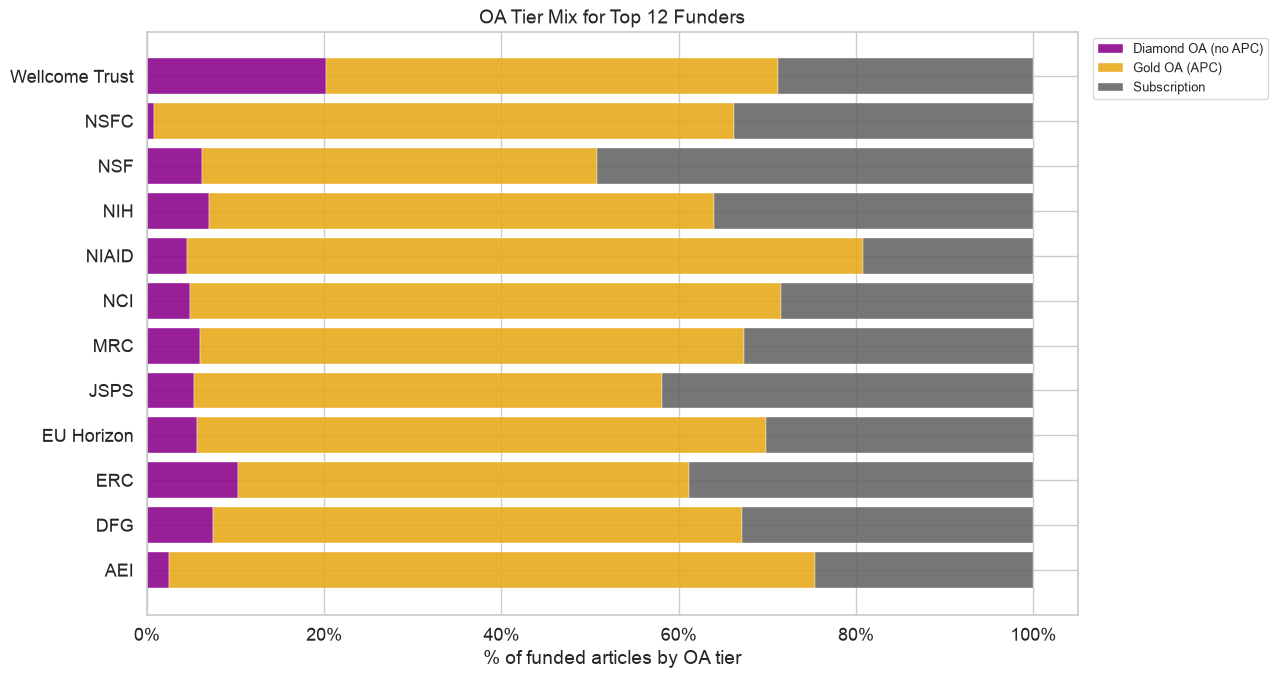

In [14]:
if not HAS_FUNDER:
    print('Skipped -- funder data not available in this database.')
else:
    df_fund = qdb("""
        SELECT af.article_id, af.funder_norm,
               a.journal_id, a.year AS year,
               dc.data_sharing_score
        FROM article_funder  af
        JOIN article         a  ON a.article_id  = af.article_id
        JOIN das_category    dc ON dc.article_id = af.article_id
        WHERE af.funder_norm != 'none' AND a.year BETWEEN 2011 AND 2025
    """)
    df_fund = df_fund.merge(
        df_journals[['journal_id','oa_tier']], on='journal_id', how='left')
    df_fund['oa_tier'] = df_fund['oa_tier'].fillna('unknown')
    df_fund_4 = df_fund[df_fund['oa_tier'].isin(tiers_4)]

    funder_tier = (df_fund_4.groupby(['funder_norm','oa_tier'])
                   .size().reset_index(name='n'))
    top_funders = (funder_tier.groupby('funder_norm')['n'].sum()
                   .nlargest(12).index.tolist())
    funder_piv  = (funder_tier[funder_tier['funder_norm'].isin(top_funders)]
                   .pivot_table(index='funder_norm', columns='oa_tier',
                                values='n', aggfunc='sum').fillna(0))
    funder_pct  = funder_piv.div(funder_piv.sum(axis=1), axis=0) * 100

    fig, ax = plt.subplots(figsize=(FIG_W, FIG_H + 2))
    bot = np.zeros(len(funder_pct))
    for t in [tt for tt in tiers_4 if tt in funder_pct.columns]:
        ax.barh(funder_pct.index, funder_pct[t], left=bot,
                color=OA_PAL[t], label=OA_LABELS[t],
                edgecolor='white', lw=0.3, alpha=0.88)
        bot += funder_pct[t].values
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_xlabel('% of funded articles by OA tier')
    ax.set_title('OA Tier Mix for Top 12 Funders')
    ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=9)
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "fig_d08_funder.png", **SAVEFIG_KWARGS)
    plt.show()


---
## 9 . Spotlight: Beilstein Journals

The **Beilstein Institut** (Frankfurt) is one of the clearest examples of
institutional diamond OA in the natural sciences. It operates two journals:

- **Beilstein Journal of Organic Chemistry** (BJOC) -- since 2005
- **Beilstein Journal of Nanotechnology** (BJNANO) -- since 2010

Both are:
- Fully peer-reviewed
- Freely readable (CC BY licence)
- **Zero author fees** -- funded entirely by the Beilstein Institut endowment
- Indexed in PubMed Central (the source of this corpus)

This section compares Beilstein against:
1. All other diamond OA journals
2. The chemistry/nanotechnology field average (all OA tiers)
3. The overall corpus

**Hypothesis**: As fully no-fee journals run by a foundation with
strong data and reproducibility norms, Beilstein papers should show
above-average data-sharing scores -- particularly for accession number provision
(standard in chemistry for crystal structures, spectra, datasets).


In [15]:
df_beil = df_art[df_art['is_beilstein']].copy()
df_other_diamond = df_art[(df_art['oa_tier']=='diamond_oa') & ~df_art['is_beilstein']].copy()
df_corpus_rest   = df_art[~df_art['is_beilstein']].copy()

print('Beilstein articles in corpus:')
print(df_beil.groupby('title')['article_id'].count().to_string())
print(f'\nTotal Beilstein: {len(df_beil):,}')
print(f'Other diamond OA: {len(df_other_diamond):,}')
print()

# Year distribution
print('Beilstein articles by year:')
print(df_beil['year'].value_counts().sort_index().to_string())


Beilstein articles in corpus:
title
Beilstein Journal of Nanotechnology       2629
Beilstein Journal of Organic Chemistry    3854

Total Beilstein: 6,483
Other diamond OA: 38,745

Beilstein articles by year:
year
2011    300
2012    352
2013    439
2014    583
2015    555
2016    488
2017    565
2018    578
2019    546
2020    430
2021    307
2022    317
2023    248
2024    405
2025    370


In [ ]:
# data-sharing score comparison: Beilstein vs other diamond vs gold-APC vs corpus
groups = {
    'Beilstein':        df_beil['data_sharing_score'],
    'Other Diamond OA': df_other_diamond['data_sharing_score'],
    'Gold OA (APC)':    df_art[df_art['oa_tier']=='gold_apc']['data_sharing_score'],
    'Hybrid':           df_art[df_art['oa_tier']=='hybrid']['data_sharing_score'],
    'Subscription':     df_art[df_art['oa_tier']=='subscription']['data_sharing_score'],
    'Corpus overall':   df_art['data_sharing_score'],
}

print('data-sharing score comparison:')
for label, s in groups.items():
    print(f'  {label:22} n={len(s):>7,}  mean={s.mean():.3f}  median={s.median():.3f}')

# Test Beilstein vs corpus
u_b, p_b = stats.mannwhitneyu(df_beil['data_sharing_score'].dropna(),
                               df_corpus_rest['data_sharing_score'].dropna(),
                               alternative='two-sided')
cles_b = u_b / (len(df_beil['data_sharing_score'].dropna()) * len(df_corpus_rest['data_sharing_score'].dropna()))
r_b = 2 * cles_b - 1
print(f'\nBeilstein vs corpus: U={u_b:.0f}, p={p_b:.3e}, r={r_b:.4f}')

# Test Beilstein vs other diamond
if len(df_other_diamond) > 0:
    u_bd, p_bd = stats.mannwhitneyu(df_beil['data_sharing_score'].dropna(),
                                    df_other_diamond['data_sharing_score'].dropna(),
                                    alternative='two-sided')
    cles_bd = u_bd / (len(df_beil['data_sharing_score'].dropna()) * len(df_other_diamond['data_sharing_score'].dropna()))
    r_bd = 2 * cles_bd - 1
    print(f'Beilstein vs other diamond: U={u_bd:.0f}, p={p_bd:.3e}, r={r_bd:.4f}')


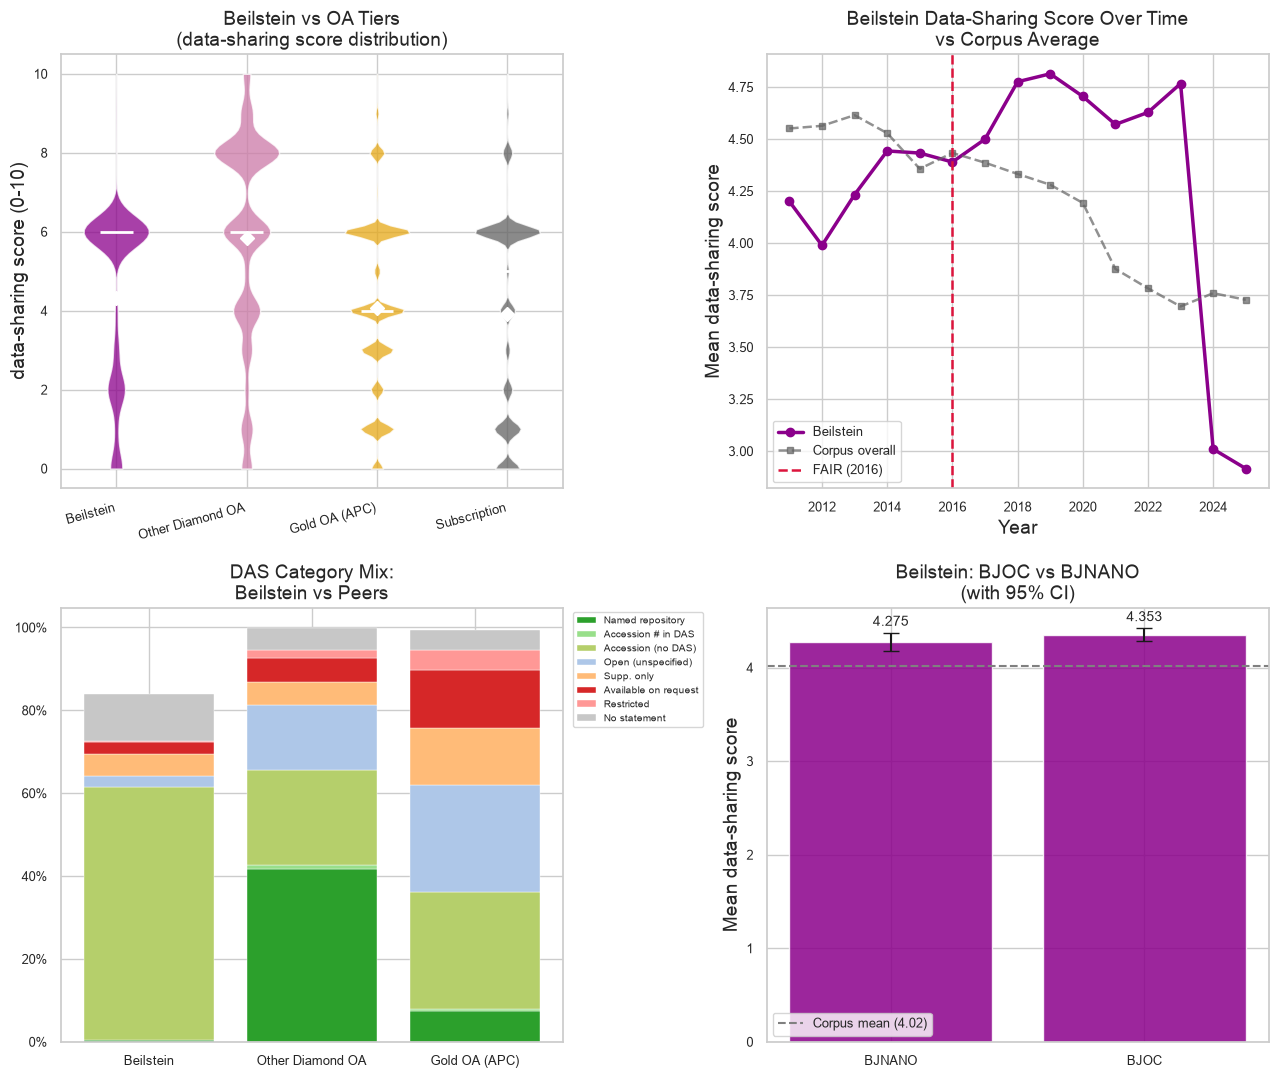

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(FIG_W, FIG_H * 2 + 1))
axes = axes.ravel()

# Panel A: Violin comparison (safe: skip empty groups)
ax = axes[0]
group_keys  = ['Beilstein','Other Diamond OA','Gold OA (APC)','Subscription']
grp_colours = ['#8b008b','#cc79a7','#e6a817','#636363']
all_arrays  = [groups[k].dropna().values for k in group_keys]

valid_idx_b  = [i for i, d in enumerate(all_arrays) if len(d) >= 2]
valid_data_b = [all_arrays[i] for i in valid_idx_b]
valid_clrs_b = [grp_colours[i] for i in valid_idx_b]
valid_pos_b  = valid_idx_b

if valid_data_b:
    parts_b = ax.violinplot(valid_data_b, positions=valid_pos_b,
                             showmedians=True, showextrema=False)
    for pc, c in zip(parts_b['bodies'], valid_clrs_b):
        pc.set_facecolor(c); pc.set_alpha(0.75)
    parts_b['cmedians'].set_color('white'); parts_b['cmedians'].set_linewidth(2)

for i, (k, d) in enumerate(zip(group_keys, all_arrays)):
    if len(d) >= 1:
        ax.plot(i, d.mean(), 'D', color='white', ms=7, zorder=5)
    else:
        ax.text(i, 5, 'no data', ha='center', fontsize=8, color='grey')

ax.set_xticks(range(4)); ax.set_xticklabels(group_keys, rotation=15, ha='right', fontsize=9)
ax.set_ylabel('data-sharing score (0-10)')
ax.set_title('Beilstein vs OA Tiers\n(data-sharing score distribution)')

# Panel B: Beilstein data-sharing score over time vs corpus
ax = axes[1]
beil_yr = df_beil.groupby('year')['data_sharing_score'].mean()
corp_yr  = df_art.groupby('year')['data_sharing_score'].mean()
ax.plot(beil_yr.index, beil_yr.values,  lw=2.5, marker='o', ms=6,
        color='#8b008b', label='Beilstein')
ax.plot(corp_yr.index, corp_yr.values,  lw=1.8, marker='s', ms=4,
        color='#636363', ls='--', label='Corpus overall', alpha=0.7)
ax.axvline(FAIR_YEAR, color='crimson', lw=1.8, ls='--', label='FAIR (2016)')
ax.set_xlabel('Year'); ax.set_ylabel('Mean data-sharing score')
ax.set_title('Beilstein Data-Sharing Score Over Time\nvs Corpus Average')
ax.legend(fontsize=9)

# Panel C: DAS category composition - Beilstein vs other diamond vs gold-APC
ax = axes[2]
comp_groups = {
    'Beilstein':        df_beil,
    'Other Diamond OA': df_other_diamond,
    'Gold OA (APC)':    df_art[df_art['oa_tier']=='gold_apc'],
}
beil_cat_piv = pd.DataFrame({
    lbl: grp.groupby('cat').size() / len(grp) * 100
    for lbl, grp in comp_groups.items()
}).fillna(0).reindex([c for c in CAT_ORDER if c != 'no_das_but_supp'])

bot_b = np.zeros(3)
for cat in beil_cat_piv.index:
    vals = beil_cat_piv.loc[cat].values if cat in beil_cat_piv.index else [0,0,0]
    ax.bar(beil_cat_piv.columns, vals, bottom=bot_b,
           color=CAT_COLOURS.get(cat,'#aaa'), label=CAT_LABELS.get(cat,cat),
           edgecolor='white', lw=0.3)
    bot_b += vals
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('DAS Category Mix:\nBeilstein vs Peers')
ax.legend(bbox_to_anchor=(1.01,1), loc='upper left', fontsize=7)

# Panel D: Beilstein BJOC vs BJNANO comparison
ax = axes[3]
beil_by_journal = df_beil.groupby('title')['data_sharing_score'].agg(
    n='count', mean='mean', median='median', std='std').reset_index()
beil_by_journal['ci95'] = 1.96 * beil_by_journal['std'] / np.sqrt(beil_by_journal['n'])
# shorten title
beil_by_journal['short'] = beil_by_journal['title'].apply(
    lambda t: 'BJOC' if 'Organic' in str(t) else ('BJNANO' if 'Nano' in str(t) else t[:20]))

bars_bj = ax.bar(beil_by_journal['short'], beil_by_journal['mean'],
                 color='#8b008b', alpha=0.85, edgecolor='white',
                 yerr=beil_by_journal['ci95'], capsize=6)
ax.bar_label(bars_bj, fmt='{:.3f}', padding=3, fontsize=10)
ax.axhline(df_art['data_sharing_score'].mean(), color='grey', lw=1.5, ls='--',
           label=f'Corpus mean ({df_art["data_sharing_score"].mean():.2f})')
ax.set_ylabel('Mean data-sharing score'); ax.legend(fontsize=9)
ax.set_title('Beilstein: BJOC vs BJNANO\n(with 95% CI)')

for ax_i in axes:
    ax_i.tick_params(labelsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d09_beilstein.png", **SAVEFIG_KWARGS)
plt.show()


In [18]:
# Beilstein quality signals vs corpus
print('Quality signal rates -- Beilstein vs corpus:')
print(f'  {"Signal":25} {"Beilstein":>12} {"Corpus":>12} {"Delta":>10}')
print('  ' + '-'*60)
for col in signal_cols:
    b_rate = df_beil[col].mean() * 100 if col in df_beil else 0
    c_rate = df_art[col].mean()  * 100 if col in df_art  else 0
    print(f'  {signal_labels[col]:25} {b_rate:>11.1f}% {c_rate:>11.1f}% {b_rate-c_rate:>+9.1f}%')

print('\nBeilstein DAS category breakdown:')
beil_cats = df_beil['cat'].value_counts(normalize=True) * 100
for cat, pct in beil_cats.items():
    print(f'  {CAT_LABELS.get(cat,cat):30} {pct:.1f}%')


Quality signal rates -- Beilstein vs corpus:
  Signal                       Beilstein       Corpus      Delta
  ------------------------------------------------------------
  License mentioned                 0.0%         0.2%      -0.1%
  DOI mentioned                     0.5%         1.5%      -1.0%
  GitHub link                       0.1%         1.3%      -1.2%
  Any URL                           0.6%         6.6%      -5.9%
  Accession number                  0.0%         3.5%      -3.5%

Beilstein DAS category breakdown:
  Accession (no DAS)             61.1%
  Supp. (no DAS)                 16.0%
  No statement                   11.4%
  Supp. only                     5.2%
  Available on request           3.1%
  Open (unspecified)             2.7%
  Named repository               0.4%
  Restricted                     0.2%
  Accession # in DAS             0.0%


---
## 10 . Journal-Level Analysis

Which specific journals lead and lag in FAIR data sharing?
We rank journals within each OA tier by mean data-sharing score (min 30 articles)
and highlight whether the top performers are consistent over time.


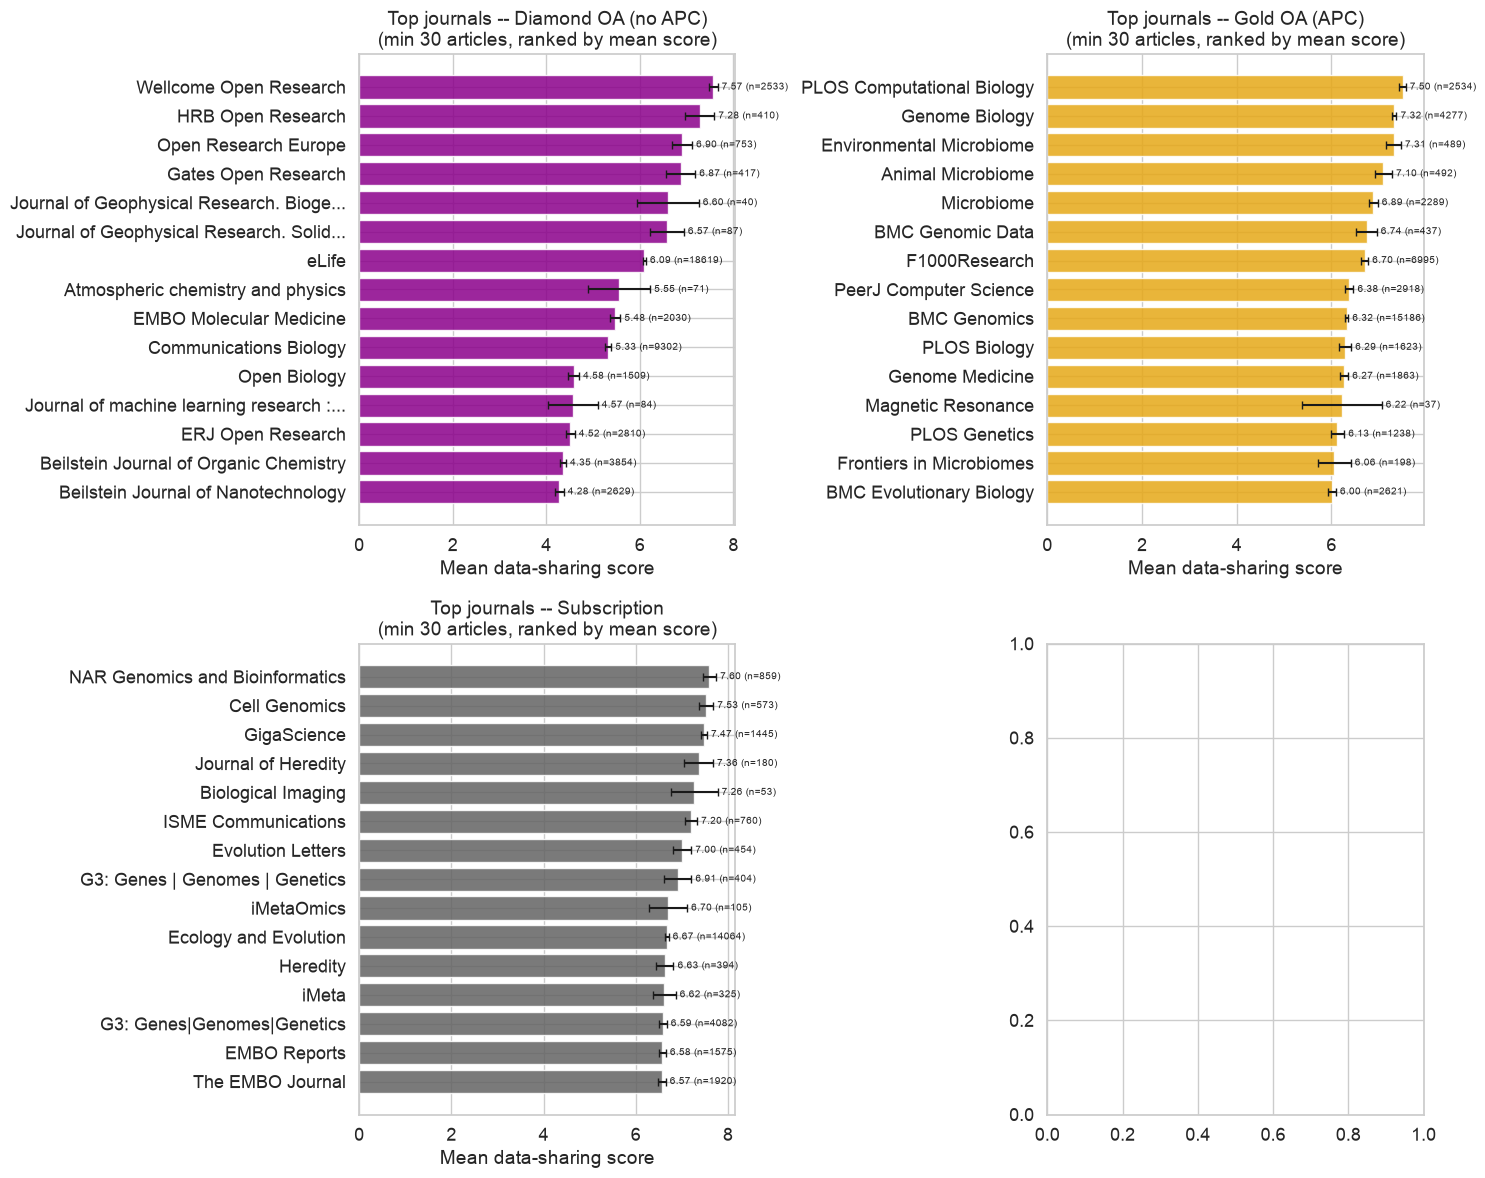

In [19]:
# Journal scores
jrnl_scores = (df_art[df_art['oa_tier'].isin(tiers_4)]
               .groupby(['journal_id','oa_tier'])['data_sharing_score']
               .agg(n='count', mean='mean', std='std').reset_index())
jrnl_scores = jrnl_scores.merge(
    df_journals[['journal_id','title','publisher']], on='journal_id', how='left')
jrnl_scores['ci95'] = 1.96 * jrnl_scores['std'] / np.sqrt(jrnl_scores['n'])
jrnl_scores = jrnl_scores[jrnl_scores['n'] >= 30]

fig, axes = plt.subplots(2, 2, figsize=(FIG_W + 2, FIG_H * 2 + 2))
axes = axes.ravel()

for ax_i, t in enumerate(tiers_4):
    ax = axes[ax_i]
    subset = (jrnl_scores[jrnl_scores['oa_tier']==t]
              .sort_values('mean', ascending=False)
              .head(15))
    if len(subset) == 0:
        ax.text(0.5, 0.5, f'Insufficient data\nfor {OA_LABELS[t]}',
                ha='center', va='center', transform=ax.transAxes)
        continue
    # Shorten titles
    subset = subset.copy()
    subset['short_title'] = subset['title'].apply(
        lambda t: (t[:38] + '...') if len(str(t)) > 40 else str(t))
    bars = ax.barh(subset['short_title'][::-1], subset['mean'][::-1],
                   xerr=subset['ci95'][::-1],
                   color=OA_PAL[t], alpha=0.85, edgecolor='white', capsize=3)
    ax.bar_label(bars,
                 labels=[f'{m:.2f} (n={int(n)})'
                         for m,n in zip(subset['mean'][::-1], subset['n'][::-1])],
                 padding=3, fontsize=7)
    ax.set_xlabel('Mean data-sharing score')
    ax.set_title(f'Top journals -- {OA_LABELS[t]}\n(min 30 articles, ranked by mean score)')

plt.tight_layout()
plt.savefig(FIGURES_DIR / "fig_d10_journals.png", **SAVEFIG_KWARGS)
plt.show()


---
## 11 . Statistical Summary Dashboard + Exports


In [ ]:
# Full summary table
print('=' * 95)
print('DIAMOND OA & FAIR -- COMPLETE STATISTICAL SUMMARY')
print('=' * 95)

diamond_scores = df_art[df_art['oa_tier']=='diamond_oa']['data_sharing_score'].dropna()

summary = []
for t in ['gold_apc','hybrid','subscription']:
    sc = df_art[df_art['oa_tier']==t]['data_sharing_score'].dropna()
    u, p = stats.mannwhitneyu(diamond_scores, sc, alternative='two-sided')
    cles_e = u / (len(diamond_scores) * len(sc))
    r_e = 2 * cles_e - 1
    summary.append({
        'Comparison': f'Diamond OA vs {OA_LABELS[t]}',
        'Diamond n':   len(diamond_scores), 'Diamond mean': round(diamond_scores.mean(),3),
        'Other n':     len(sc),             'Other mean':   round(sc.mean(),3),
        'Gap':         round(diamond_scores.mean()-sc.mean(),3),
        'p-value':     f'{p:.2e}',          'Effect r':     round(r_e,4),
        'Sig': '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns')),
    })

# Beilstein rows
for label, sc in [('Corpus overall', df_corpus_rest['data_sharing_score'].dropna()),
                   ('Other Diamond OA', df_other_diamond['data_sharing_score'].dropna())]:
    if len(sc) == 0: continue
    beil_sc = df_beil['data_sharing_score'].dropna()
    u, p = stats.mannwhitneyu(beil_sc, sc, alternative='two-sided')
    cles_e2 = u / (len(beil_sc) * len(sc))
    r_e = 2 * cles_e2 - 1
    summary.append({
        'Comparison': f'Beilstein vs {label}',
        'Diamond n':   len(beil_sc),       'Diamond mean': round(beil_sc.mean(),3),
        'Other n':     len(sc),            'Other mean':   round(sc.mean(),3),
        'Gap':         round(beil_sc.mean()-sc.mean(),3),
        'p-value':     f'{p:.2e}',         'Effect r':     round(r_e,4),
        'Sig': '***' if p<0.001 else ('**' if p<0.01 else ('*' if p<0.05 else 'ns')),
    })

df_summary = pd.DataFrame(summary)
print(df_summary.to_string(index=False))
print('\nEffect r: <0.1 negligible | 0.1-0.3 small | 0.3-0.5 medium | >0.5 large')


In [21]:
# Key findings narrative
d_mean = diamond_scores.mean()
g_mean = df_art[df_art['oa_tier']=='gold_apc']['data_sharing_score'].mean()
h_mean = df_art[df_art['oa_tier']=='hybrid']['data_sharing_score'].mean()
s_mean = df_art[df_art['oa_tier']=='subscription']['data_sharing_score'].mean()
b_mean = df_beil['data_sharing_score'].mean()
c_mean = df_art['data_sharing_score'].mean()

print(f'''
+--------------------------------------------------------------------+
|   DIAMOND OA & FAIR DATA SHARING -- KEY FINDINGS                 |
+--------------------------------------------------------------------+
|  OA tier ranking by mean data-sharing score:                              |
|    Diamond OA  : {d_mean:.3f}                                        |
|    Gold APC    : {g_mean:.3f}                                        |
|    Hybrid      : {h_mean:.3f}                                        |
|    Subscription: {s_mean:.3f}                                        |
|    Corpus mean : {c_mean:.3f}                                        |
|                                                                    |
|  Beilstein vs corpus mean  : {b_mean - c_mean:+.3f}                           |
|  Diamond OA vs gold APC    : {d_mean - g_mean:+.3f}                           |
|  Diamond OA vs subscription: {d_mean - s_mean:+.3f}                           |
+--------------------------------------------------------------------+
''')



+--------------------------------------------------------------------+
|   DIAMOND OA & FAIR DATA SHARING -- KEY FINDINGS                 |
+--------------------------------------------------------------------+
|  OA tier ranking by mean data-sharing score:                              |
|    Diamond OA  : 5.618                                        |
|    Gold APC    : 4.056                                        |
|    Hybrid      : nan                                        |
|    Subscription: 3.913                                        |
|    Corpus mean : 4.018                                        |
|                                                                    |
|  Beilstein vs corpus mean  : +0.304                           |
|  Diamond OA vs gold APC    : +1.562                           |
|  Diamond OA vs subscription: +1.704                           |
+--------------------------------------------------------------------+



In [22]:
# Exports
export_dir = Path('../results/fair_diamond_exports')
export_dir.mkdir(parents=True, exist_ok=True)

exports = {
    'journal_oa_tiers.csv':          df_journals[['journal_id','title','publisher',
                                                   'issn_epub','issn_ppub',
                                                   'oa_tier','n_articles']],
    'article_oa_scores.csv':         df_art[['article_id','year','oa_tier',
                                             'is_beilstein','data_sharing_score','cat']],
    'tier_stats.csv':                tier_stats,
    'score_by_tier_year.csv':        score_yr,
    'das_categories_by_tier.csv':    piv_pct.reset_index(),
    'quality_signals_by_tier.csv':   sig_tier.reset_index(),
    'beilstein_articles.csv':        df_beil[['article_id','year','title',
                                              'data_sharing_score','cat']],
    'summary_statistics.csv':        df_summary,
}

for fname, df_e in exports.items():
    df_e.to_csv(export_dir / fname, index=False)
    print(f'  Saved {fname}  ({len(df_e):,} rows)')

con.close()
print('\nDone. Database connection closed.')


  Saved journal_oa_tiers.csv  (21,955 rows)


  Saved article_oa_scores.csv  (6,874,176 rows)
  Saved tier_stats.csv  (3 rows)
  Saved score_by_tier_year.csv  (45 rows)
  Saved das_categories_by_tier.csv  (3 rows)
  Saved quality_signals_by_tier.csv  (3 rows)
  Saved beilstein_articles.csv  (6,483 rows)
  Saved summary_statistics.csv  (5 rows)

Done. Database connection closed.
